# **AIRBNB DATASET PROJECT- STATISTICAL THINKING**


This is an analysis of Airbnb Boston listings dataset . The question we want to answer is: "What factors are associated with Airbnb prices, and can we quantify the uncertainty in those relationships?" we'll be following these steps:
### **Exploratory Data Analysis (EDA)**
    • What does the distribution of Airbnb prices look like? 
    • What's the median price? 
    • Are there extreme outliers? 
    • How does price vary by neighborhood? 
    • Reviews price
### **Probability / simulation** 
       What's the probability that a randomly selected Airbnb costs more than $200/night? we'll use a simulation to understand the uncertainty around our estimate. 
### **Bootstrap** 
    For example: What's the 95% confidence interval for a given price? We can bootstrap the dataset and construct the confidence interval ourselves rather than relying on a black-box function. 
### **Hypothesis testing** 
       Are Airbnb prices significantly different between two neighborhoods? Then we will perform a permutation test. 
### **Correlation**
       Is the number of reviews correlated with price? Or: Is minimum-night requirement correlated with price? And calculate Pearson's rr. 
### **Linear regression**
    How much does price tend to change as the number of bedrooms increases? Then we build a regression and use a pairs bootstrap to estimate uncertainty around the slope.

## LOADING THE DATA AND THE LIBRARIES

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib as mpl
import matplotlib.dates as mdates

plt.style.use('ggplot')
%matplotlib inline

In [1]:
from pathlib import Path
data_path = Path("listings.csv")
data_listings = pd.read_csv(data_path)

In [4]:
data_listing.info()

<class 'pandas.DataFrame'>
RangeIndex: 3585 entries, 0 to 3584
Data columns (total 95 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   id                                3585 non-null   int64  
 1   listing_url                       3585 non-null   str    
 2   scrape_id                         3585 non-null   int64  
 3   last_scraped                      3585 non-null   str    
 4   name                              3585 non-null   str    
 5   summary                           3442 non-null   str    
 6   space                             2528 non-null   str    
 7   description                       3585 non-null   str    
 8   experiences_offered               3585 non-null   str    
 9   neighborhood_overview             2170 non-null   str    
 10  notes                             1610 non-null   str    
 11  transit                           2295 non-null   str    
 12  access           

In [5]:
data_listing['review_scores_rating'].head(10)

0      NaN
1     94.0
2     98.0
3    100.0
4     99.0
5    100.0
6     90.0
7     96.0
8     96.0
9     94.0
Name: review_scores_rating, dtype: float64

In [6]:
data_listing['review_scores_value'].head()

0     NaN
1     9.0
2    10.0
3    10.0
4    10.0
Name: review_scores_value, dtype: float64

## **EXPLORATORY DATA ANALYSIS**

* **What does the distribution of Airbnb prices look like?**

In [4]:
# First lets get the prices from str to float 
price_data_list = data_listing['price'].tolist()    #.tolist() converts a Pandas Series or NumPy array into a regular Python list.
price_list = [float(item.replace(',' , '')[1:]) for item in price_data_list]
data_listing['price'] = price_list
data_listing.info()

<class 'pandas.DataFrame'>
RangeIndex: 3585 entries, 0 to 3584
Data columns (total 95 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   id                                3585 non-null   int64  
 1   listing_url                       3585 non-null   str    
 2   scrape_id                         3585 non-null   int64  
 3   last_scraped                      3585 non-null   str    
 4   name                              3585 non-null   str    
 5   summary                           3442 non-null   str    
 6   space                             2528 non-null   str    
 7   description                       3585 non-null   str    
 8   experiences_offered               3585 non-null   str    
 9   neighborhood_overview             2170 non-null   str    
 10  notes                             1610 non-null   str    
 11  transit                           2295 non-null   str    
 12  access           

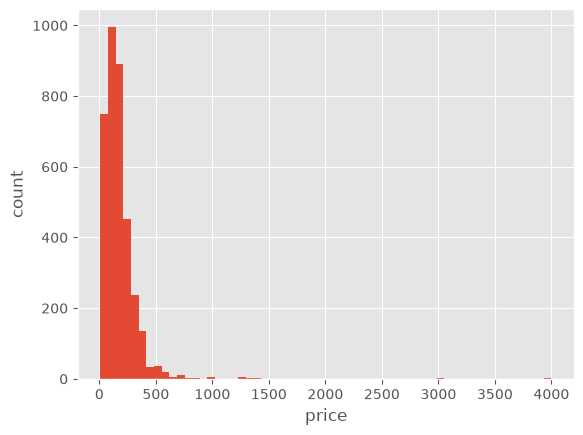

In [8]:
# Compute number of data points: n_data
n_data = len(data_listing['price'])

# Number of bins is the square root of number of data points: n_bins
bin = np.sqrt(n_data)

# Convert number of bins to integer: n_bins
n_bins = int(bin)

# Plot the histogram
plt.hist(data_listing['price'], bins=n_bins)

# Label axes
plt.xlabel('price')
plt.ylabel('count')
plt.show()


Initial look at the prices showss that they are mostly below 300$, with a few outliers.

    To get an idea of the distribution of price, we can also use summary statistics

In [5]:
print("Mean:", np.mean(price_list))
print("Median:", np.median(price_list))
print("Min:", np.min(price_list))
print("Max:", np.max(price_list))
print("Standard deviation:", np.std(price_list))

Mean: 173.9258019525802
Median: 150.0
Min: 10.0
Max: 4000.0
Standard deviation: 148.31063208042326


These statistics suggest our data is strongly right-skewed and has substantial variability.
The average observation is about 174.
Median = 150 — half the observations are ≤150 and half are ≥150.
Mean > median — this is a classic sign of right skewness. A relatively small number of large values are pulling the mean upward.
Min = 10, Max = 4,000 — the range is enormous (3,990), suggesting some very large observations or potential outliers, that may influence the mean.
Standard deviation = 148.31 — observations vary considerably around the mean. The SD is about 85% of the mean, which indicates substantial dispersion.


In [6]:
# IQR method
Q1 = np.percentile(data_listing['price'], 25)
Q3 = np.percentile(data_listing['price'], 75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = [p for p in data_listing['price']
            if p < lower_bound or p > upper_bound]

print("Number of outliers:", len(outliers))
print("Outliers:", outliers)

Number of outliers: 124
Outliers: [429.0, 500.0, 450.0, 750.0, 480.0, 550.0, 500.0, 450.0, 500.0, 500.0, 525.0, 725.0, 872.0, 500.0, 500.0, 500.0, 500.0, 500.0, 425.0, 559.0, 425.0, 425.0, 600.0, 1400.0, 536.0, 450.0, 450.0, 450.0, 450.0, 650.0, 625.0, 525.0, 600.0, 1300.0, 600.0, 550.0, 575.0, 500.0, 600.0, 800.0, 450.0, 700.0, 450.0, 650.0, 500.0, 449.0, 1250.0, 425.0, 695.0, 479.0, 450.0, 464.0, 450.0, 451.0, 975.0, 600.0, 450.0, 550.0, 425.0, 568.0, 699.0, 550.0, 600.0, 450.0, 500.0, 450.0, 600.0, 500.0, 599.0, 680.0, 1000.0, 450.0, 425.0, 769.0, 600.0, 1235.0, 650.0, 849.0, 1345.0, 700.0, 499.0, 690.0, 600.0, 500.0, 500.0, 425.0, 550.0, 425.0, 449.0, 600.0, 1372.0, 570.0, 429.0, 4000.0, 500.0, 750.0, 603.0, 603.0, 1275.0, 699.0, 999.0, 450.0, 500.0, 3000.0, 603.0, 500.0, 600.0, 500.0, 1250.0, 506.0, 603.0, 506.0, 700.0, 500.0, 450.0, 700.0, 500.0, 500.0, 1000.0, 500.0, 500.0, 524.0, 550.0, 459.0]


In [7]:
outlier_counts = pd.Series(outliers).value_counts().sort_index()

<Axes: >

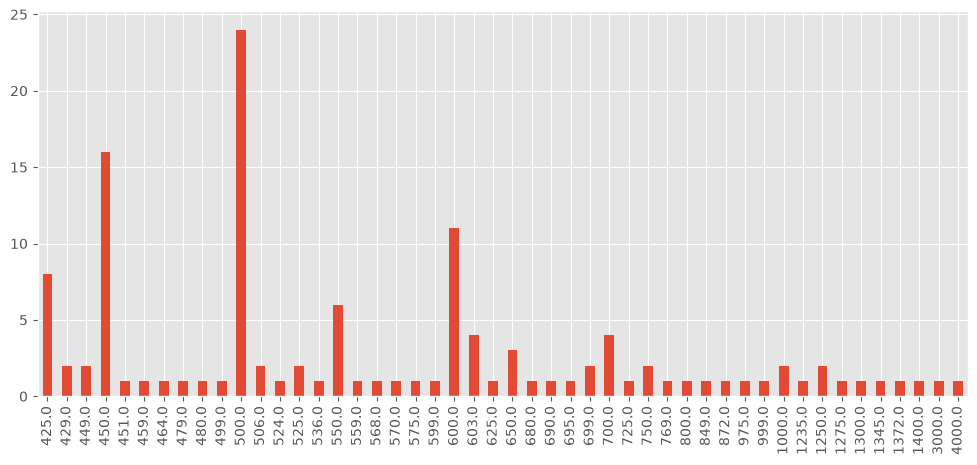

In [8]:

outlier_counts.plot(kind="bar", figsize=(12, 5))


The dataset appears to have a substantial number of high-value observations, not just one or two isolated extreme values.
The dataset contains 124 observations identified as statistical outliers. The outliers are predominantly on the upper end of the distribution, with many values ranging from approximately 425 to 700 and several substantially larger observations, including values of 1,400, 3,000, and 4,000. This pattern is consistent with the positive skewness observed in the data, where the mean (173.93) exceeds the median (150.00).

Let's take a closer look at the prices between 1000 and $4000

In [43]:

cols = [
    'price',
    'bedrooms',
   
    'review_scores_value',
    'neighbourhood_cleansed',
    'property_type'
]

selected = data_listing[
    data_listing['price'].between(1000, 4000)
][cols]


pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', None)
pd.set_option('display.width', None)

print(selected)


       price  bedrooms  review_scores_value   neighbourhood_cleansed  \
793   1400.0       1.0                  NaN                  Roxbury   
1022  1300.0       5.0                 10.0                South End   
1262  1250.0       3.0                 10.0                 Back Bay   
1764  1000.0       2.0                  NaN              Charlestown   
1896  1235.0       1.0                  NaN              Beacon Hill   
1950  1345.0       1.0                  NaN              Beacon Hill   
2204  1372.0       1.0                  NaN                   Fenway   
2285  4000.0       1.0                  NaN                   Fenway   
2448  1275.0       1.0                  NaN                   Fenway   
3055  3000.0       2.0                  NaN  South Boston Waterfront   
3096  1250.0       1.0                  NaN  South Boston Waterfront   
3242  1000.0       3.0                 10.0             South Boston   

     property_type  
793      Apartment  
1022         House  


    Will remove the 3000 and $4000 outliers to get a more accurate analysis of the prices in general in Boston.

In [9]:
# Remove the 2 largest values
data_listing = data_listing.drop(data_listing["price"].nlargest(2).index)


In [15]:
print("Mean:", np.mean(data_listing["price"]))
print("Median:", np.median(data_listing["price"]))
print("Min:", np.min(data_listing["price"]))
print("Max:", np.max(data_listing["price"]))
print("Standard deviation:", np.std(data_listing["price"]))

Mean: 172.06921574099917
Median: 150.0
Min: 10.0
Max: 1400.0
Standard deviation: 125.26046191717124


The drop of the two biggest price didn't have an impact on the median, its still 150. But as expected the value of the mean dropped to 172, but not much (from $173), still larger than the median due to the right skewness of the prices. 
The standard deviation went from 143 to 125, removing the 2 biggest outliers reduced the variability aound the mean. The variabbility remains important nonetheless due to the other 122 outliers detected, that are mostly on the higher end.
We will leave the remaining outliers since we think they still reflect real prices in certain area that just happen to be higher.

    Let's take a closer look at some of the 50 of the smallest prices of this dataset

In [7]:
data_listing[['price', 'bedrooms', 'bathrooms', 'neighbourhood_cleansed',
              'property_type', 'review_scores_value']].dropna().sort_values(
                  'price'
              ).head(50)

,price,bedrooms,bathrooms,neighbourhood_cleansed,property_type,review_scores_value
3468,11.0,1.0,1.0,Allston,Apartment,10.0
3450,20.0,1.0,1.5,Allston,House,8.0
777,22.0,1.0,1.0,Roxbury,House,9.0
267,22.0,1.0,1.0,Jamaica Plain,Apartment,8.0
382,25.0,1.0,1.0,Jamaica Plain,Apartment,8.0
3529,25.0,1.0,0.5,Allston,Apartment,4.0
3532,28.0,1.0,1.0,Allston,Apartment,10.0
502,28.0,1.0,1.0,Mission Hill,Apartment,8.0
2813,29.0,1.0,1.0,Dorchester,Apartment,10.0
243,29.0,1.0,1.0,Jamaica Plain,Apartment,10.0


Looking at the 50 lowest-priced listings provides an indication of the characteristics associated with lower prices. Most of these listings are one-bedroom properties with one bathroom, and apartments are the most common property type. The listings are spread across several neighbourhoods, particularly Allston, Dorchester, Roxbury, and Jamaica Plain. Review scores are generally high, suggesting that the low prices are not necessarily associated with poor reviews. 

• **How does price vary by neighborhood?**

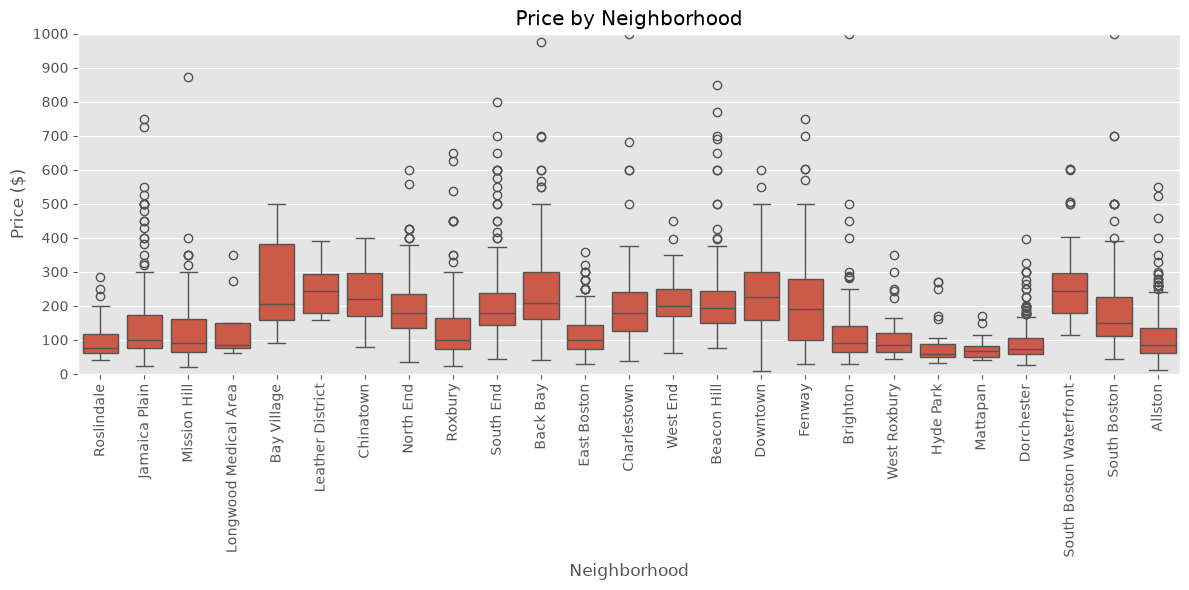

In [8]:
plt.figure(figsize=(12, 6))

sns.boxplot(
    data=data_listing,
    x='neighbourhood_cleansed',
    y='price'
)

plt.xlabel("Neighborhood")
plt.ylabel("Price ($)")
plt.title("Price by Neighborhood")

# Y-axis: $0 to $500, with $100 intervals
plt.ylim(0, 1000)
plt.yticks(range(0, 1001, 100))

plt.xticks(rotation=90)
plt.tight_layout()
plt.show()


 Prices vary considerably by neighborhood. Some neighborhoods have substantially higher median prices than others, while some have lower and more consistent prices. This suggests that neighborhood is an important factor associated with listing prices.

The boxplot gives as a closer look on where our outliers are. The unusually highest prices are noted in fenway and South boston waterfront, respectively 4000 and 3000$. Some of the highest price, therefore most of the outliers at: South end, Beacon hill, roxbury, Blackway. The most affordable places appear to be: Mattapan, East Boston, Hide Park, Roslindale, Brighton, Dorchester

What the relationship between reviews and price look like

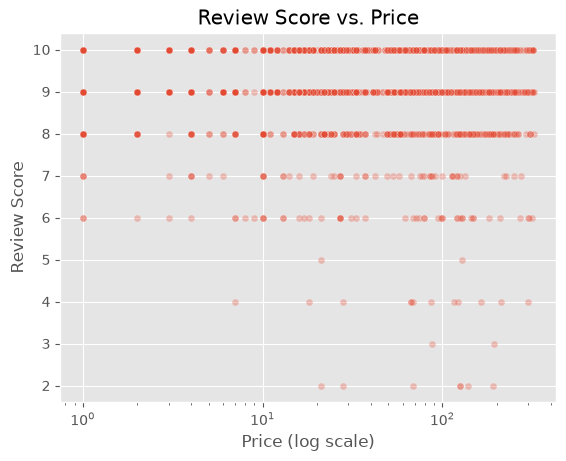

In [8]:
sns.scatterplot(
    data=data_listing,
    x="price",
    y="review_scores_value",
    alpha=0.3,
    s=25
)

plt.xscale("log")
plt.title("Review Score vs. Price")
plt.xlabel("Price (log scale)")
plt.ylabel("Review Score")
plt.show()


## **PROBABILITY AND SIMULATION**

**What is the probability that a randomly selected Airbnb costs more than $200 per night?**

In [9]:
### 1. Calculate the observed probability
# Remove missing prices
prices = data_listing['price'].dropna()

# Proportion of listings costing more than $200
probability = (prices > 200).mean()

print(f"Estimated probability: {probability:.2%}")

Estimated probability: 27.78%


Approximately **28% of Airbnb listings cost more than $200 per night**.

In [11]:
# Use of simulation to understand uncertainty
# We can repeatedly sample listings and calculate the proportion above $200:

prices = data_listing['price']

n = len(prices)
simulations = 10000
sample_size = 100

simulated_probs = []

for _ in range(simulations):
    sample = np.random.choice(prices, size=sample_size, replace=True)
    simulated_probs.append((sample > 200).mean())

simulated_probs = np.array(simulated_probs)
simulated_probs 

array([0.28, 0.29, 0.2 , ..., 0.27, 0.28, 0.3 ], shape=(10000,))

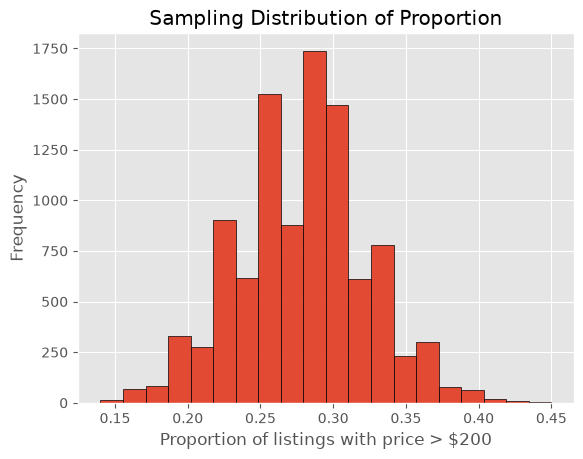

In [12]:
plt.hist(simulated_probs, bins=20, edgecolor='black')

plt.xlabel("Proportion of listings with price > $200")
plt.ylabel("Frequency")
plt.title("Sampling Distribution of Proportion")

plt.show()


**Based on the sample, approximately 28% of Airbnb listings cost more than $200 per night. A simulation of 10,000 samples suggests that the estimated probability typically falls between 25% and 30%.**

In [13]:
#Calculate a 95% interval

lower = np.percentile(simulated_probs, 2.5)
upper = np.percentile(simulated_probs, 97.5)

print(f"95% simulation interval: {lower:.2%} to {upper:.2%}")

95% simulation interval: 19.00% to 37.00%


The estimated proportion of listings priced above $200 is approximately 28%, with a 95% simulation interval of 19% to 37%.


## **BOOSTRAP**

How much would the median change if we had collected a different sample of listings?
That's what bootstrapping helps us investigate.

We repeatedly sample from your existing dataset with replacement, calculate the median each time, and look at the distribution of those medians. We'll then estimate a confidence interval for the median.

The mean is heavily affected by the 500 and $1,000 listings, whereas the median is much more resistant to extreme values.

In [14]:
bootstrap_medians = []

for _ in range(10_000):
    sample = np.random.choice(prices, size=n, replace=True)
    bootstrap_medians.append(np.median(sample))

ci_lower = np.percentile(bootstrap_medians, 2.5)
ci_upper = np.percentile(bootstrap_medians, 97.5)

print("Sample median:", np.median(prices))
print("95% CI:", ci_lower, ci_upper)

Sample median: 150.0
95% CI: 145.0 150.0


 - **`Sample median`**: The median of the observed price is 150`, so half of your observed prices are ≤ 150 and half are ≥ 150.
- **`95% CI`**: based on the bootstrap procedure, the plausible sampling range for the population median is approximately 145–150.

## **HYPOTHESIS TESTING**

We're doing a permutation test to see whether there is evidence of a difference in the **mean prices** between two neighbourhoods. We'll choose neighborhoods that seam to have similar values from looking at our boxplot. 
Our hypotheses:

 - **Null hypothesis $H_0$:** There is no difference in mean price between Longwood Medical Area and Roslindale.

 $$
H_0: \mu_{\text{Longwood}} - \mu_{\text{Roslindale}} = 0
$$

 - **Alternative hypothesis $H_A$:** There is a difference in mean price between the two neighbourhoods.

 $$
H_A: \mu_{\text{Longwood}} - \mu_{\text{Roslindale}} \neq 0
$$

We asking: If there really were no difference between the neighbourhoods, how often would randomly shuffling the prices produce a difference at least as large as the one we actually observed?
-**Choosen significance level: α = 0.05**

In [15]:
a = data_listing.loc[data_listing["neighbourhood_cleansed"] == "Longwood Medical Area", "price"]
b = data_listing.loc[data_listing["neighbourhood_cleansed"] == "Roslindale", "price"]

observed = np.mean(a) - np.mean(b)

combined = np.concatenate([a, b])
n_a = len(a)

permuted_diffs = []

for _ in range(10_000):
    shuffled = np.random.permutation(combined)

    perm_a = shuffled[:n_a]
    perm_b = shuffled[n_a:]

    permuted_diffs.append(np.mean(perm_a) - np.mean(perm_b))

p_value = np.mean(np.abs(permuted_diffs) >= abs(observed))

print("Observed difference:", observed)
print("Permutation p-value:", p_value)

Observed difference: 40.01587301587303
Permutation p-value: 0.0706


 $$
H_0: \mu_{\text{Longwood}} - \mu_{\text{South End}} = 0
$$

 $$
H_A: \mu_{\text{Longwood}} - \mu_{\text{West End}} \neq 0
$$


In [18]:
a = data_listing.loc[data_listing["neighbourhood_cleansed"] == "South End", "price"]
b = data_listing.loc[data_listing["neighbourhood_cleansed"] == "West End", "price"]

observed = np.mean(a) - np.mean(b)

combined = np.concatenate([a, b])
n_a = len(a)

permuted_diffs = []

for _ in range(10_000):
    shuffled = np.random.permutation(combined)

    perm_a = shuffled[:n_a]
    perm_b = shuffled[n_a:]

    permuted_diffs.append(np.mean(perm_a) - np.mean(perm_b))

p_value = np.mean(np.abs(permuted_diffs) >= abs(observed))

print("Observed difference:", observed)
print("Permutation p-value:", p_value)

Observed difference: -5.242143483160135
Permutation p-value: 0.7696


 $$
H_0: \mu_{\text{Longwood}} - \mu_{\text{Hyde Park}} = 0
$$

 $$
H_A: \mu_{\text{Longwood}} - \mu_{\text{Mattapan}} \neq 0
$$


In [19]:
a = data_listing.loc[data_listing["neighbourhood_cleansed"] == "Hyde Park", "price"]
b = data_listing.loc[data_listing["neighbourhood_cleansed"] == "Mattapan", "price"]

observed = np.mean(a) - np.mean(b)

combined = np.concatenate([a, b])
n_a = len(a)

permuted_diffs = []

for _ in range(10_000):
    shuffled = np.random.permutation(combined)

    perm_a = shuffled[:n_a]
    perm_b = shuffled[n_a:]

    permuted_diffs.append(np.mean(perm_a) - np.mean(perm_b))

p_value = np.mean(np.abs(permuted_diffs) >= abs(observed))

print("Observed difference:", observed)
print("Permutation p-value:", p_value)

Observed difference: 11.423387096774192
Permutation p-value: 0.4506


For all three Permutation tests, p > 0.05,  evidence against the alternative hypothesis and concludes that the neighborhoods compared don't have statistically different prices.

## **CORRELATION**

We will calculate **Pearson's correlation coefficient $r$**.

Pearson's $r$ ranges from $-1$ to $+1$:

 - $r \approx +1$: strong positive linear relationship
- $r \approx 0$: little/no linear relationship
- $r \approx -1$: strong negative linear relationship

In [12]:
from scipy.stats import pearsonr

data = data_listing[["review_scores_value", "price"]].dropna()

r, p_value = pearsonr(
    data["review_scores_value"],
    data["price"]
)

print("Pearson r:", r)
print("p-value:", p_value)


Pearson r: 0.01183351494086188
p-value: 0.534025573696722


It appears the reviews score and the price don't have a linear relationship. 
The p value

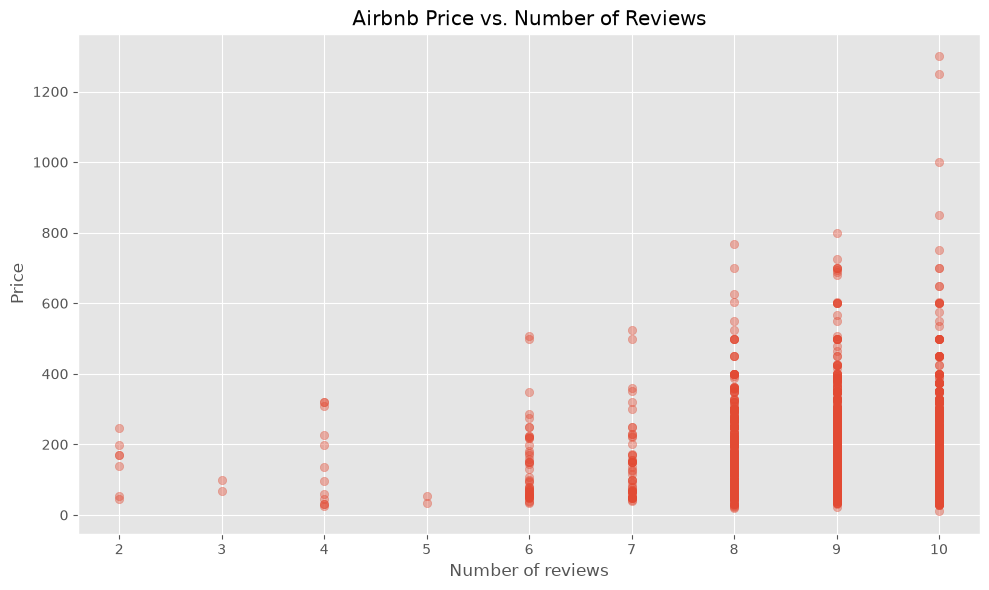

In [15]:
IS THIS REALLY PERTINENT AT THIS STAGE
""""4. Correlation — price vs. reviews
Scatterplot"""
plt.figure(figsize=(10, 6))

plt.scatter(
    data_listing['review_scores_value'],
    data_listing['price'],
    alpha=0.4
)

plt.xlabel("Number of reviews")
plt.ylabel("Price")
plt.title("Airbnb Price vs. Number of Reviews")

plt.tight_layout()
plt.show()

 **Is the minimum-night requirement correlated with price?**

In [13]:
data = data_listing[["minimum_nights", "price"]]

r, p_value = pearsonr(
    data["minimum_nights"],
    data["price"]
)

print("Pearson r:", r)
print("p-value:", p_value)

Pearson r: 0.02005390884230461
p-value: 0.22997348867667666


In [20]:
rho, p = stats.spearmanr(
    data_listing['minimum_nights'],
    data_listing['price']
)

print("Spearman correlation:", rho)
print("p-value:", p)

Spearman correlation: 0.2188848629964819
p-value: 3.831446104945755e-40


## **LINEAR REGRESSION**

**How much does price tend to change as the number of bedrooms increases?**

In [14]:
from sklearn.linear_model import LinearRegression

data = data_listing[["bedrooms", "price"]].dropna()

x = data["bedrooms"].values
y = data["price"].values

n = len(data)
slopes = []

for _ in range(10_000):
    indices = np.random.choice(n, size=n, replace=True)

    x_boot = x[indices].reshape(-1, 1)
    y_boot = y[indices]

    model = LinearRegression()
    model.fit(x_boot, y_boot)

    slopes.append(model.coef_[0])

slope = LinearRegression().fit(
    x.reshape(-1, 1), y
).coef_[0]

ci_lower = np.percentile(slopes, 2.5)
ci_upper = np.percentile(slopes, 97.5)

print("Estimated slope:", slope)
print("95% bootstrap CI:", ci_lower, ci_upper)




Estimated slope: 75.98492171380765
95% bootstrap CI: 68.82038964112942 83.6974093261121


 Each additional bedroom is associated with an estimated $75 increase in nightly price, with a 95% bootstrap confidence interval of $68 to $83.


**I**

**I**

In [26]:
""""5. Linear regression — bedrooms vs. price
Set up X and y:"""

from sklearn.linear_model import LinearRegression
df_lr=data_listing[['bedrooms', 'price']].dropna()

X = df_lr['bedrooms'].values.reshape(-1, 1)
y = df_lr['price']

#Fit the model:

model = LinearRegression()

model.fit(X, y)

intercept = model.intercept_
slope = model.coef_[0]

print("Intercept:", intercept)
print("Slope:", slope)
#The regression equation is:

print(
    f"Predicted price = {intercept:.2f} + "
    f"{slope:.2f} × bedrooms"
)

Intercept: 78.37474167972128
Slope: 75.98492171380765
Predicted price = 78.37 + 75.98 × bedrooms


**I**

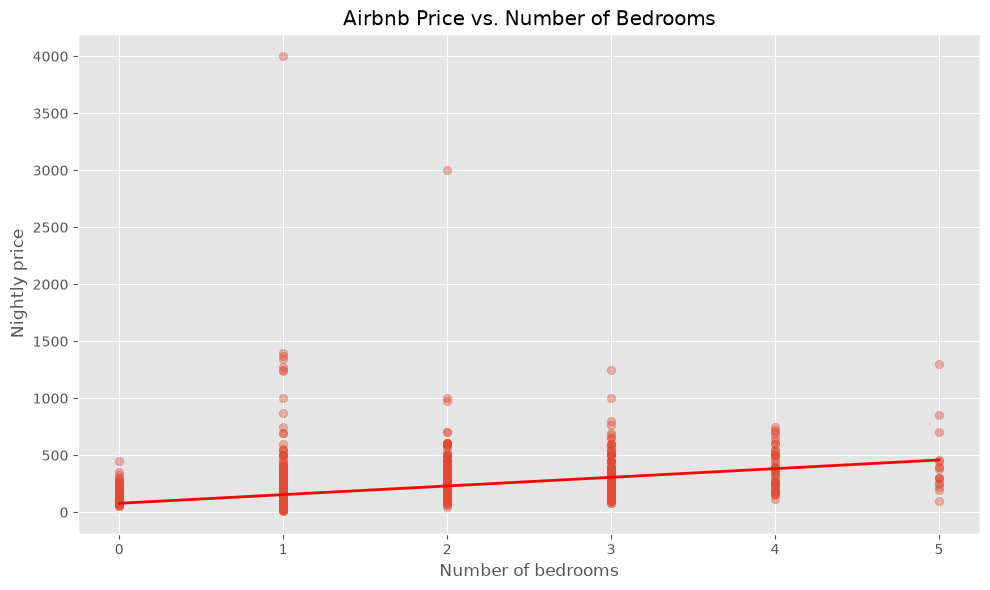

In [29]:
#Regression graph
plt.figure(figsize=(10, 6))

plt.scatter(
    df_lr['bedrooms'],
    df_lr['price'],
    alpha=0.4
)

x_line = np.linspace(
    df_lr['bedrooms'].min(),
    df_lr['bedrooms'].max(),
    100
).reshape(-1, 1)

y_line = model.predict(x_line)

plt.plot(
    x_line,
    y_line,
    color='red',
    linewidth=2
)

plt.xlabel("Number of bedrooms")
plt.ylabel("Nightly price")
plt.title("Airbnb Price vs. Number of Bedrooms")

plt.tight_layout()
plt.show()


**I**

Observed slope: 75.98492171380765
95% bootstrap CI: 68.64357886120587 to 83.61994652895044


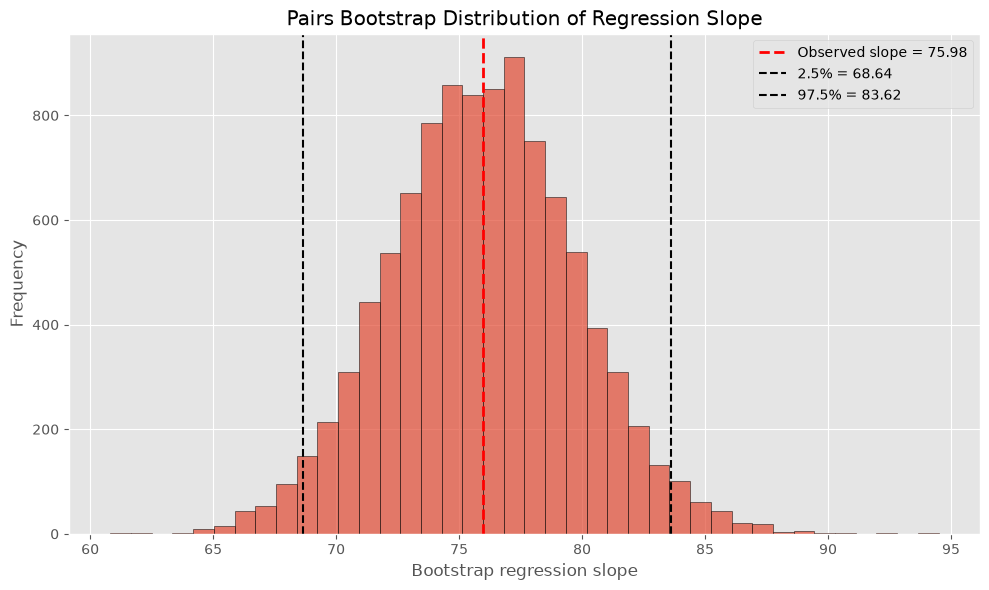

In [31]:
"""6. Pairs bootstrap for the regression slope

#Instead of bootstrapping price alone, we resample the bedrooms-price pairs together.

X_values = df_lr['bedrooms'].values
y_values = df_lr['price'].values

n = len(df_lr)
n_bootstrap = 10000

bootstrap_slopes = []

for i in range(n_bootstrap):

    # Randomly select observations with replacement
    indices = np.random.choice(
        np.arange(n),
        size=n,
        replace=True
    )

    X_sample = X_values[indices].reshape(-1, 1)
    y_sample = y_values[indices]

    # Fit regression
    model_boot = LinearRegression()
    model_boot.fit(X_sample, y_sample)

    # Store slope
    bootstrap_slopes.append(
        model_boot.coef_[0]
    )

bootstrap_slopes = np.array(bootstrap_slopes)

#95% CI for the slope
slope_ci_lower = np.percentile(
    bootstrap_slopes,
    2.5
)

slope_ci_upper = np.percentile(
    bootstrap_slopes,
    97.5
)

print("Observed slope:", slope)
print(
    "95% bootstrap CI:",
    slope_ci_lower,
    "to",
    slope_ci_upper
)

#Plot bootstrap slopes
plt.figure(figsize=(10, 6))

plt.hist(
    bootstrap_slopes,
    bins=40,
    edgecolor='black',
    alpha=0.7
)

plt.axvline(
    slope,
    color='red',
    linestyle='--',
    linewidth=2,
    label=f"Observed slope = {slope:.2f}"
)

plt.axvline(
    slope_ci_lower,
    color='black',
    linestyle='--',
    label=f"2.5% = {slope_ci_lower:.2f}"
)

plt.axvline(
    slope_ci_upper,
    color='black',
    linestyle='--',
    label=f"97.5% = {slope_ci_upper:.2f}"
)

plt.xlabel("Bootstrap regression slope")
plt.ylabel("Frequency")
plt.title("Pairs Bootstrap Distribution of Regression Slope")
plt.legend()

plt.tight_layout()
plt.show()




**I**